[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L2/BA_L2_lppl_btc2017/BA_L2_lppl_btc2017.ipynb)

# BA_L2_lppl_btc2017: Bitcoin 2017: an LPPL Fit

*Quantlet of Lecture 2, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Log-periodic power law (LPPL) fit of the Bitcoin daily log close on 1 January to 1 December 2017, two-step estimation (OLS for the linear parameters, Nelder-Mead search over the critical time, the exponent and the log-frequency from 300 random starts), with the estimated critical time against the actual peak of 16 December 2017.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts
END = '2026-09-18'


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))


def prices(sym):
    # every positive daily close in the file, to 18 September 2026
    return daily(sym, END)


def rets(p, start='2018-01-01'):
    # daily log returns in percent, r_t = 100 (ln P_t - ln P_{t-1})
    return (100 * np.log(p).diff()).dropna().loc[start:]

## Model and estimation

The **log-periodic power law** (LPPL) describes the log price before a critical time $t_c$:

$$\ln P_t = A + B\,(t_c - t)^m + C\,(t_c - t)^m \cos\!\big(\omega \ln(t_c - t) - \phi\big) + \varepsilon_t, \qquad t < t_c.$$

$B < 0$ and $0 < m < 1$ give super-exponential growth; $C$ is the amplitude and $\omega$ the log-frequency of
oscillations that speed up towards $t_c$. With $C_1 = C\cos\phi$ and $C_2 = C\sin\phi$ the model is linear in
$(A, B, C_1, C_2)$ for given $(t_c, m, \omega)$:

$$\ln P_t = A + B f_t + C_1 g_t + C_2 h_t + \varepsilon_t, \quad f_t = (t_c - t)^m,\ g_t = f_t\cos(\omega\ln(t_c - t)),\ h_t = f_t\sin(\omega\ln(t_c - t)).$$

Estimation has two steps: ordinary least squares (OLS) for $(A, B, C_1, C_2)$, and a Nelder–Mead search over
$(t_c, m, \omega)$ that minimises the sum of squared errors, restricted to $0.1 \le m \le 0.9$, $6 \le \omega \le 13$
and $t_c$ after the last observation. The search has many local minima, so it starts from many random points.
$t_c$ is the critical time implied by the fitted model, not a guaranteed date of the crash.

Here: time $t$ in years since 1 January 2017; three windows start on 1 January 2017 and end on 15 November,
1 December and 8 December 2017; 300 random starts each (random seed 7). The chart shows the window ending on
1 December 2017.

**How to read the chart.** Orange: the Bitcoin close on a log scale; blue: the fitted LPPL curve up to $\hat t_c$;
dotted green: the end of the estimation window; dashed red: the estimated critical time. The window was chosen after
the crash, so the fit is retrospective, not a dated forecast.

In [5]:
from scipy.optimize import minimize

p_btc = prices('BTC-USD.CC')
T0 = pd.Timestamp('2017-01-01')          # time t is in years since 1 January 2017


def design(t, tc, m, om):
    # regressors of the linear part: 1, f_t, g_t, h_t
    dt = tc - t; f = dt ** m
    return np.column_stack([np.ones_like(t), f, f * np.cos(om * np.log(dt)), f * np.sin(om * np.log(dt))])


def sse(th, t, y):
    # sum of squared errors after OLS for (A, B, C1, C2); infinite outside the bounds
    tc, m, om = th
    if tc <= t[-1] + 1e-3 or not (0.1 <= m <= 0.9) or not (6 <= om <= 13):
        return 1e9
    X = design(t, tc, m, om); coef, *_ = np.linalg.lstsq(X, y, rcond=None)
    return float(((y - X @ coef) ** 2).sum())


def lppl_fit(end, rng, starts, maxiter=4000):
    # best of `starts` Nelder-Mead searches over (t_c, m, omega) from random starting points
    s_ = p_btc.loc[T0:end]
    t = ((s_.index - T0).days.values / 365.25).astype(float); y = np.log(s_.values)
    best = None
    for _ in range(starts):
        x0 = [t[-1] + rng.uniform(0.005, 0.25), rng.uniform(0.1, 0.9), rng.uniform(6, 13)]
        r_ = minimize(sse, x0, args=(t, y), method='Nelder-Mead', options={'xatol': 1e-6, 'fatol': 1e-8, 'maxiter': maxiter})
        if best is None or r_.fun < best.fun:
            best = r_
    tc, m, om = best.x
    coef = np.linalg.lstsq(design(t, tc, m, om), y, rcond=None)[0]
    resid = y - design(t, tc, m, om) @ coef
    tcd = T0 + pd.Timedelta(days=tc * 365.25)
    return dict(end=pd.Timestamp(end), n=len(y), tc=tcd, lead=(tcd - pd.Timestamp(end)).days, m=m, omega=om,
                B=coef[1], C_over_B=np.hypot(coef[2], coef[3]) / abs(coef[1]),
                R2=1 - (resid ** 2).sum() / ((y - y.mean()) ** 2).sum(), t=t, theta=(tc, m, om), coef=coef)

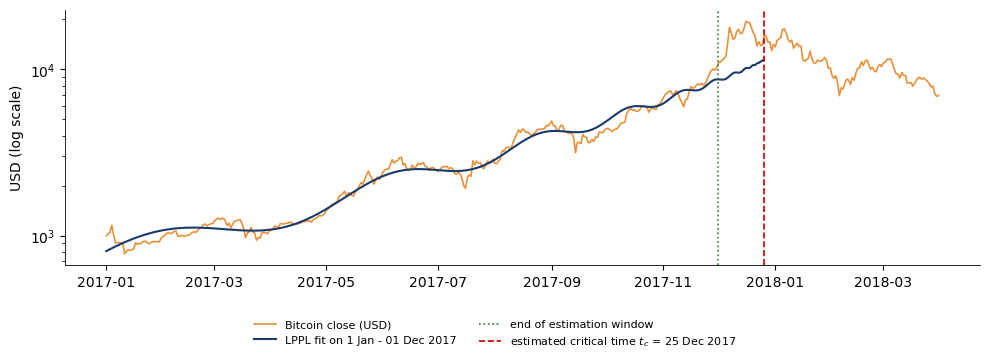

In [6]:
rng = np.random.default_rng(7)
fits = [lppl_fit(e, rng, 300) for e in ['2017-11-15', '2017-12-01', '2017-12-08']]
f = fits[1]
tc, m, om = f['theta']
tt = np.linspace(f['t'][0], tc - 1e-4, 800)
yy = design(tt, tc, m, om) @ f['coef']
dates = [T0 + pd.Timedelta(days=v * 365.25) for v in tt]
seg = p_btc.loc['2017-01-01':'2018-03-31']

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(seg.index, seg.values, color=BTC, lw=1.2, label='Bitcoin close (USD)')
ax.plot(dates, np.exp(yy), color=BLUE, lw=1.5, label=f"LPPL fit on 1 Jan - {f['end']:%d %b %Y}")
ax.axvline(f['end'], color=GREEN, ls=':', lw=1.2, label='end of estimation window')
ax.axvline(f['tc'], color=RED, ls='--', lw=1.2, label=f"estimated critical time $t_c$ = {f['tc']:%d %b %Y}")
ax.set_yscale('log'); ax.set_ylabel('USD (log scale)')
slide_legend(fig, 0.14, ncol=2)
save_fig(fig, 'ba_l2_lppl_btc2017')

Estimates of the three windows (lead: days from the end of the window to $\hat t_c$) and the actual peak.

In [7]:
tab = pd.DataFrame([{'window ends': f_['end'].date(), 'n': f_['n'], 't_c': f_['tc'].date(), 'lead (days)': f_['lead'],
                     'm': f_['m'], 'omega': f_['omega'], 'B': f_['B'], '|C|/|B|': f_['C_over_B'], 'R2': f_['R2']}
                    for f_ in fits]).set_index('window ends')
print(tab.round(3).to_string())
peak = p_btc.loc['2017-11-01':'2018-01-31']
print(f"\nActual peak: {peak.idxmax():%d %B %Y} at {peak.max():,.0f} USD; "
      f"fall to the low of 2018: {100 * (1 - p_btc.loc['2018'].min() / peak.max()):.0f}%")

               n         t_c  lead (days)      m   omega      B  |C|/|B|     R2
window ends                                                                    
2017-11-15   319  2018-01-04           50  0.900  13.000 -2.759    0.089  0.980
2017-12-01   335  2017-12-25           24  0.851  12.492 -2.837    0.088  0.982
2017-12-08   342  2017-12-08            0  0.741  11.144 -2.898    0.081  0.979

Actual peak: 16 December 2017 at 19,497 USD; fall to the low of 2018: 83%
